<div >
    <img src = "../banner.jpg" />
</div>

<a href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture14/01_SpatialData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Datos espaciales y validación cruzada espacial

Cuando los no observables estan correlacionados en el espacio y el modelo es flexible, la validación cruzada aleatoria **subestima** el error fuera de muestra: el fold de validación queda pegado al de entrenamiento y comparte sus nos obserbales. La CV espacial lo corrige separando geográficamente los folds.

Veamos en los datos

## Llamando las librerías

In [23]:
# install.packages("pacman") #Correr esta linea en Google Colab

In [24]:
require("pacman")
p_load("tidyverse", "sf", "modeldata", "caret", "spatialsample", "ranger")

In [25]:
set.seed(20261111)

## Los datos: viviendas en Ames, Iowa

Usamos la base `ames` del paquete `modeldata`: ventas de viviendas con sus características y su latitud y longitud. Para que todo corra rápido en clase nos quedamos con los diez barrios con más observaciones.

In [26]:
data("ames", package = "modeldata")

barrios <- c("North_Ames", "College_Creek", "Old_Town", "Edwards", "Somerset",
             "Northridge_Heights", "Gilbert", "Sawyer", "Northwest_Ames", "Sawyer_West")

ames <- ames %>%
  filter(Neighborhood %in% barrios) %>%
  mutate(Neighborhood = droplevels(Neighborhood))

dim(ames)
table(ames$Neighborhood)

[1] 2063   74


        North_Ames      College_Creek           Old_Town            Edwards 
               443                267                239                194 
          Somerset Northridge_Heights            Gilbert             Sawyer 
               182                166                165                151 
    Northwest_Ames        Sawyer_West 
               131                125 

### El objeto espacial

`st_as_sf()` convierte el `data.frame` en un objeto `sf`: cada fila tiene ahora una geometría (un punto). Las coordenadas vienen en grados (EPSG:4326, el sistema de los GPS). Ojo con el orden: primero la longitud (x), después la latitud (y).

Para medir distancias en metros la proyectamos a UTM zona 15N (EPSG:26915), el sistema proyectado que corresponde a Iowa. En Bogotá usaríamos MAGNA-SIRGAS / Origen Nacional (EPSG:9377).

In [27]:
ames_sf <- st_as_sf(ames, coords = c("Longitude", "Latitude"), crs = 4326, remove = FALSE) %>%
  st_transform(crs = 26915)

class(ames_sf)

[1] "sf"         "tbl_df"     "tbl"        "data.frame"

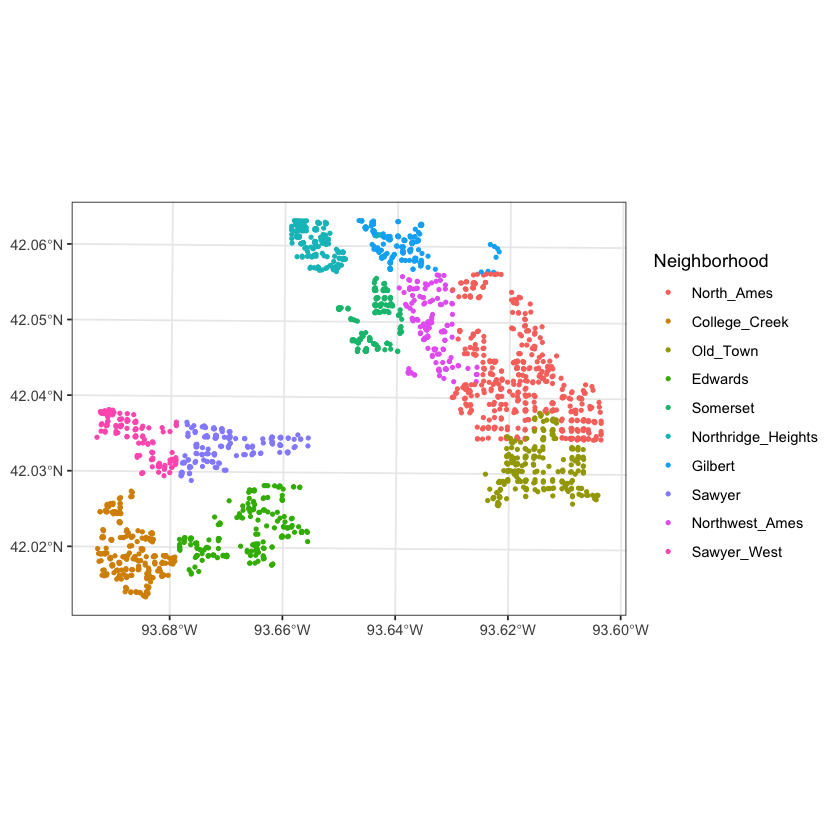

In [28]:
ggplot(ames_sf) +
  geom_sf(aes(color = Neighborhood), size = 0.8) +
  theme_bw()

## ¿Hay dependencia espacial?

Ajustamos una regresión simple del log del precio sobre el tamaño de la vivienda y miramos los residuos en el mapa. Si el modelo capturara todo lo que importa, los residuos se verían como ruido sin patrón.

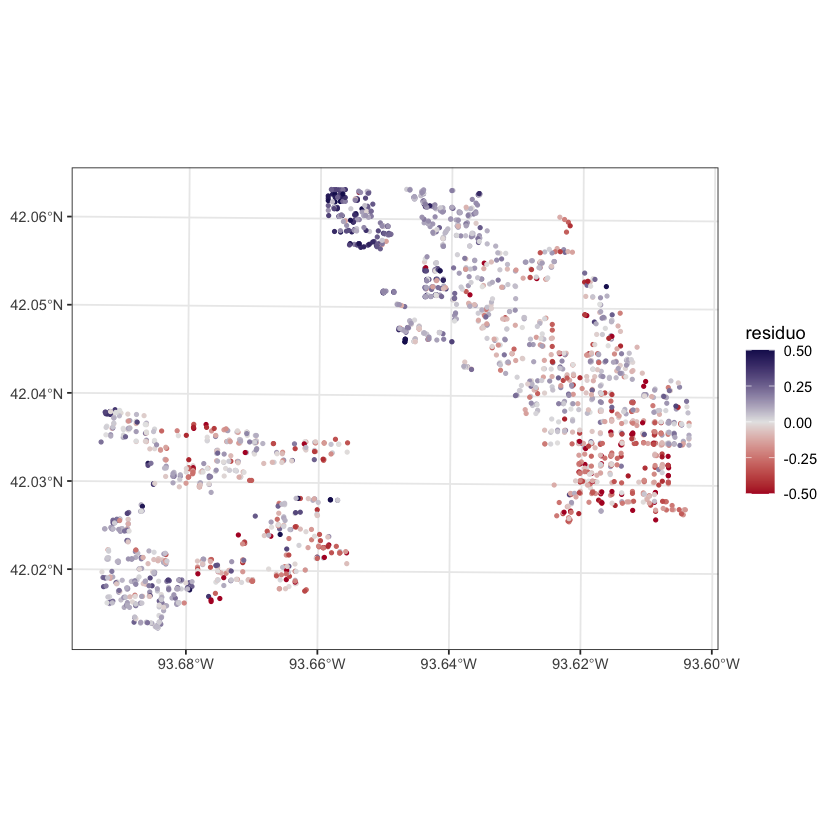

In [29]:
modelo_simple <- lm(log(Sale_Price) ~ Gr_Liv_Area + Lot_Area + Garage_Area, data = ames_sf)
ames_sf$residuo <- resid(modelo_simple)

ggplot(ames_sf) +
  geom_sf(aes(color = residuo), size = 0.8) +
  scale_color_gradient2(low = "#B2182B", mid = "grey90", high = "#1B175E",
                        limits = c(-0.5, 0.5), oob = scales::squish) +  # unos pocos residuos extremos no dominan la escala
  theme_bw()

Los residuos forman grupos: hay zonas donde el modelo subpredice sistemáticamente y zonas donde sobrepredice. Esto nos sugiere que $\text{Cov}(\varepsilon(s_i), \varepsilon(s_j)) \neq 0$.

Miremos los residuos espaciales, para medirlo, calculamos para cada vivienda el **promedio del residuo de sus 10 vecinos más cercanos**.

In [30]:
distancias <- st_distance(ames_sf)          # matriz n x n, en metros
distancias <- matrix(as.numeric(distancias), nrow = nrow(ames_sf))
diag(distancias) <- Inf                     # una vivienda no es vecina de sí misma

vecinos <- t(apply(distancias, 1, order))[, 1:10]
ames_sf$residuo_vecinos <- apply(vecinos, 1, function(v) mean(ames_sf$residuo[v]))

cor(ames_sf$residuo, ames_sf$residuo_vecinos)

[1] 0.5974001

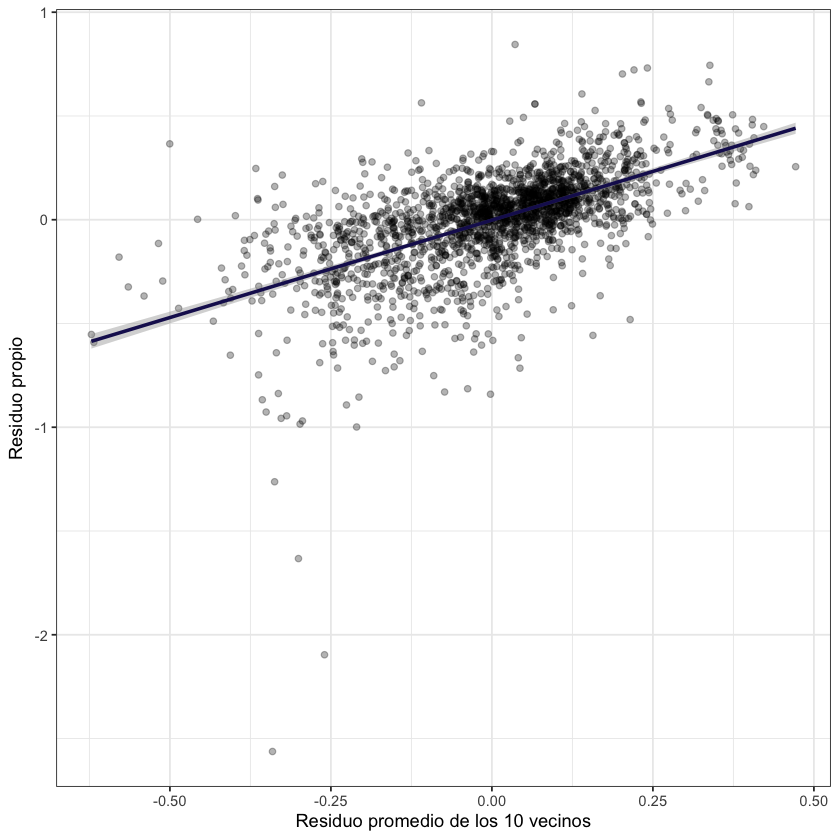

In [31]:
ggplot(ames_sf, aes(residuo_vecinos, residuo)) +
  geom_point(alpha = 0.3) +
  geom_smooth(method = "lm", formula = y ~ x, color = "#1B175E") +
  labs(x = "Residuo promedio de los 10 vecinos", y = "Residuo propio") +
  theme_bw()

La correlación es alta: conocer el residuo de los vecinos dice mucho del residuo propio. 

## Tres formas de armar folds espaciales

El paquete `spatialsample` arma los folds; lo que hacemos con ellos después (entrenar, validar, promediar) es la CV de siempre.

### Bloques

`spatial_block_cv()` divide el mapa en una grilla y asigna **bloques enteros** a cada fold (Roberts et al., 2017).

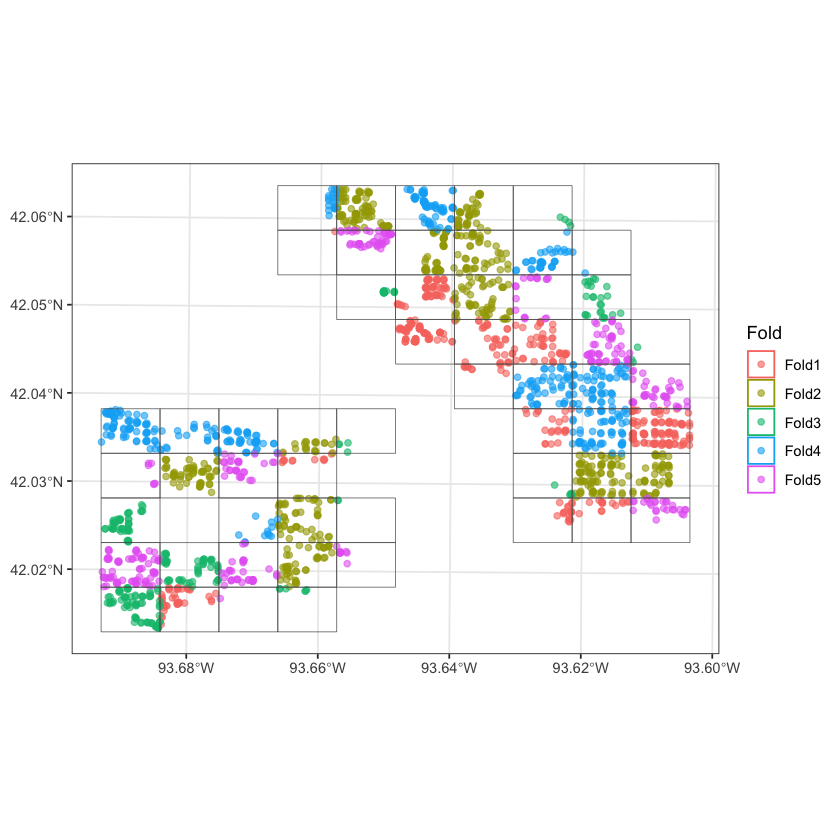

In [32]:
block_folds <- spatial_block_cv(ames_sf, v = 5)
autoplot(block_folds) + theme_bw()

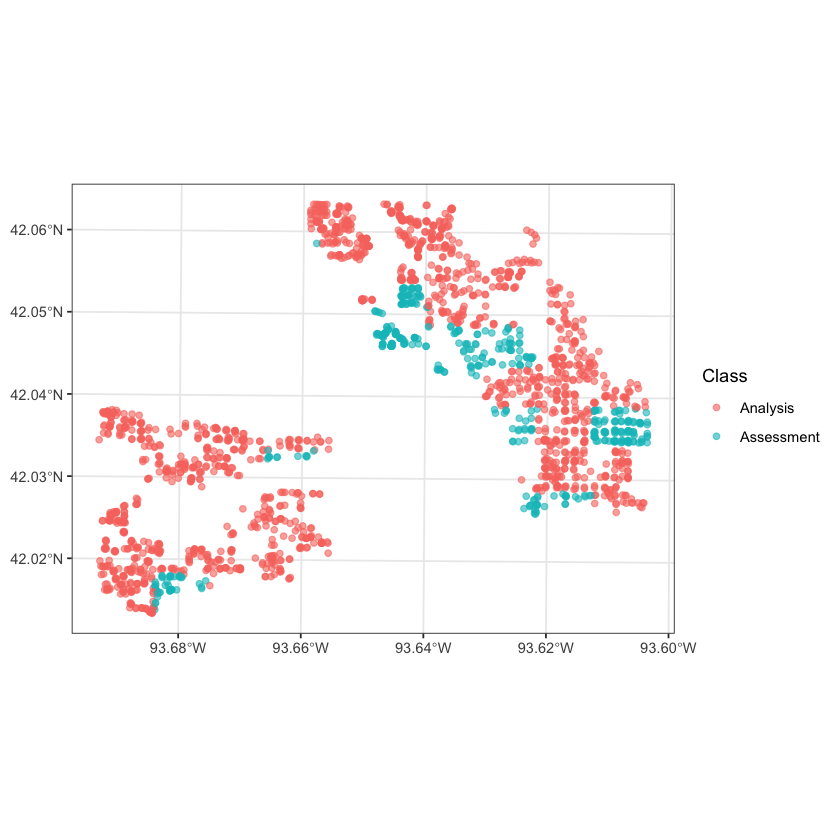

In [33]:
autoplot(block_folds$splits[[1]]) + theme_bw()

### Leave-location-out

Si ya sabemos qué unidades están relacionadas, podemos usar esos grupos como bloques. Aquí cada fold deja afuera un barrio completo.

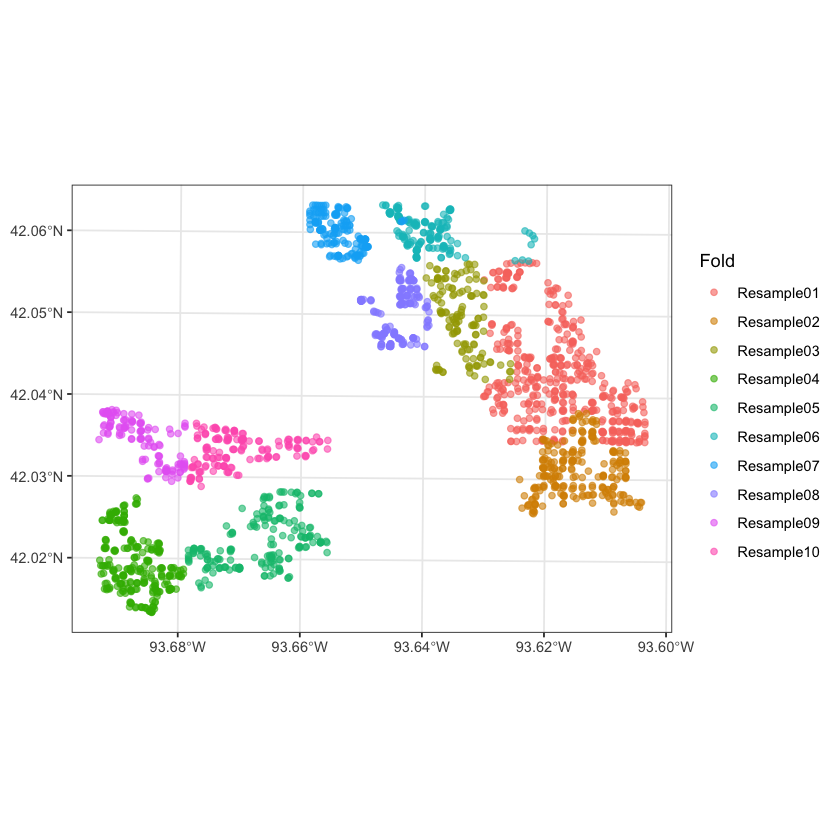

In [34]:
location_folds <- spatial_leave_location_out_cv(ames_sf, group = Neighborhood)
autoplot(location_folds) + theme_bw()

### Buffers

`spatial_buffer_vfold_cv()` arma folds y además saca del entrenamiento las viviendas que están a menos de `buffer` metros del fold de validación. Como proyectamos los datos, las distancias están en metros.

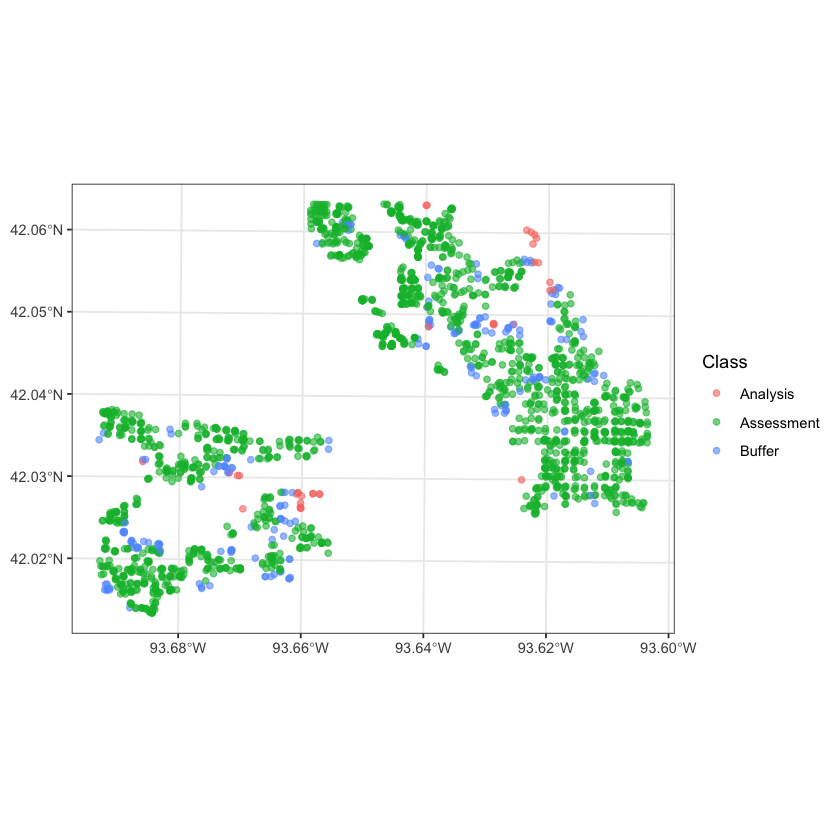

In [35]:
buffer_folds <- spatial_buffer_vfold_cv(ames_sf, v = 10, radius = 200, buffer = 200)
autoplot(buffer_folds$splits[[3]]) + theme_bw()

Las viviendas marcadas como `Buffer` forman la franja que no se usa ni para entrenar ni para validar. Su ancho debería ser del orden de la distancia a la que los residuos dejan de estar correlacionados.

## Imitando al Taller 3

Simulamos la situación del taller:

- **Test** → `North_Ames`: un barrio entero que el modelo nunca ve al entrenar, como Chapinero en el taller.
- **Entrenamiento** → los otros 9 barrios.


In [36]:
test  <- ames_sf %>% filter(Neighborhood == "North_Ames")
train <- ames_sf %>% filter(Neighborhood != "North_Ames")

c(train = nrow(train), test = nrow(test))

train  test 
 1620   443

### Random forest con coordenadas

Vamos a usar un modelo que tiene la posibilidad de aprender el lugar: agregamos las coordenadas $(x, y)$ como variables y usamos un random forest. Con coordenadas, el bosque puede aprender "en esta esquina los precios son altos", es decir, el ruido local que comparten las viviendas vecinas.

Vamos a usear dos timpos de validacion, la aleatoria y la espacial:

- `en_aleatoria`:  5 folds al azar 
- `en_espacial`: Leave-one-neighborhood-out 

Para la CV espacial armamos los folds con `spatialsample` y se los pasamos a `caret`. 

In [37]:
folds_barrio <- spatial_leave_location_out_cv(train, group = Neighborhood)
indices_barrio <- map(folds_barrio$splits, ~ .x$in_id)

Las variables: `Gr_Liv_Area` (área construida), `Lot_Frontage` (frente del lote), `Lot_Area` (área del lote), `First_Flr_SF` (área del primer piso) y `Garage_Area` (área del garaje) y las coordenadas:

In [38]:
coordenadas <- st_coordinates(ames_sf)
ames_sf$x <- coordenadas[, 1]
ames_sf$y <- coordenadas[, 2]

test  <- ames_sf %>% filter(Neighborhood == "North_Ames")
train <- ames_sf %>% filter(Neighborhood != "North_Ames")

fml_rf <- log(Sale_Price) ~ Gr_Liv_Area + Lot_Frontage + Lot_Area + First_Flr_SF + Garage_Area + x + y

grilla_rf <- expand.grid(mtry = c(2, 4, 7), splitrule = "variance", min.node.size = c(1, 5, 20))

In [39]:
rf_aleatoria <- train(fml_rf,
                      data      = st_drop_geometry(train),
                      method    = "ranger",
                      trControl = trainControl(method = "cv", number = 5),
                      metric    = "MAE",
                      tuneGrid  = grilla_rf,
                      num.trees = 200)

rf_espacial <- train(fml_rf,
                     data      = st_drop_geometry(train),
                     method    = "ranger",
                     trControl = trainControl(method = "cv", index = indices_barrio),
                     metric    = "MAE",
                     tuneGrid  = grilla_rf,
                     num.trees = 200)

In [40]:
resumen <- bind_rows(
  tibble(Modelo   = c("RF + coordenadas, CV aleatoria", "RF + coordenadas, CV espacial"),
         MAE_CV   = c(min(rf_aleatoria$results$MAE), min(rf_espacial$results$MAE)),
         MAE_test = c(mae_log(log(test$Sale_Price), predict(rf_aleatoria, newdata = st_drop_geometry(test))),
                      mae_log(log(test$Sale_Price), predict(rf_espacial,  newdata = st_drop_geometry(test)))))
) %>%
  mutate(Brecha = MAE_test - MAE_CV)

resumen

Modelo,MAE_CV,MAE_test,Brecha
<chr>,<dbl>,<dbl>,<dbl>
"RF + coordenadas, CV aleatoria",0.1105576,0.1532556,0.042698060
"RF + coordenadas, CV espacial",0.1639528,0.1550879,-0.008864859


La CV aleatoria subestima el error de generalizacion, en cada fold aleatorio, las viviendas de validación tienen vecinas en el entrenamiento y el bosque sobreajusta. La CV espacial no cae en la trampa porque cada fold de validación es un barrio que el modelo no vio en el entrenamiento.

### Extrapolación

En el taller hay un problema adicional: el barrio de test no es solo un lugar nuevo, sus viviendas pueden ser distintas a las del entrenamiento. Comparemos la distribución de las variables de `North_Ames` con la del resto.

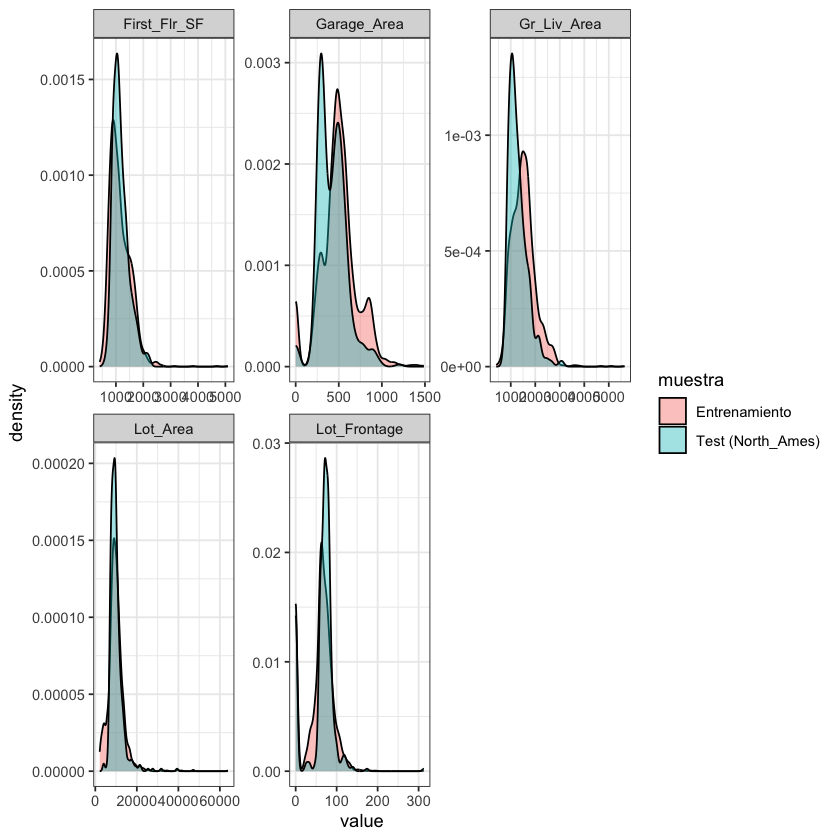

In [41]:
bind_rows(
  st_drop_geometry(train) %>% mutate(muestra = "Entrenamiento"),
  st_drop_geometry(test)  %>% mutate(muestra = "Test (North_Ames)")
) %>%
  select(muestra, Gr_Liv_Area, Lot_Frontage, Lot_Area, First_Flr_SF, Garage_Area) %>%
  pivot_longer(-muestra) %>%
  ggplot(aes(value, fill = muestra)) +
  geom_density(alpha = 0.4) +
  facet_wrap(~ name, scales = "free") +
  theme_bw()

En Ames las distribuciones se parecen bastante: `North_Ames` es un barrio típico. En el taller no es así  Chapinero es más caro que el resto de Bogotá. Cuando las $X$ del test caen fuera del rango del entrenamiento, el modelo tiene que **extrapolar**, y cada modelo lo hace de manera distinta, los modelos lineales con una recta, los arboles con las hojas.

Una forma de hacerlo es tratar de "curar" los datos para que se parezcan lo más posible al ejercicio final.
